# Checkpoint 1: Exploring FIDE rating lists, all formats (Team 25)

**Question:** Is the growth in India's high-rated and titled chess players a steady trend or did it accelerate after specific events, and is it unusual compared with other federations?

FIDE keeps three separate rating lists: **standard** (classical), **rapid** and **blitz**. We explore all three. Sections 1-4 use one format at a time (set `FORMAT` below); section 5 compares the formats.

Run order: `scripts/01_list_and_download.py` -> `02_parse_to_parquet.py` -> `03_build_monthly_summary.py`, then this notebook.

Data coverage: FIDE's archive starts Feb 2015. After each section, write 2-3 lines in the *Notes* cell.

In [1]:
from pathlib import Path
import glob
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT

FORMAT = "standard"        # change to "rapid" or "blitz" and re-run sections 1-4

all_formats = pd.read_csv(ROOT / "data/processed/summary.csv")
if "format" not in all_formats.columns:
    all_formats["format"] = "standard"
all_formats["date"] = pd.to_datetime(all_formats["snapshot"] + "-01")
all_formats = all_formats.sort_values(["format", "country", "date"])
summary = all_formats[all_formats["format"] == FORMAT].copy()

EVENTS = {"COVID lockdowns (Mar 2020)": "2020-03-01",
          "Chennai Olympiad (Aug 2022)": "2022-08-01",
          "Gukesh world title (Dec 2024)": "2024-12-01"}

def mark_events(ax):
    lo, hi = ax.get_xlim()
    for label, d in EVENTS.items():
        x = pd.Timestamp(d)
        if lo <= ax.xaxis.convert_xunits(x) <= hi:
            ax.axvline(x, ls="--", lw=1, color="grey")
            ax.text(x, ax.get_ylim()[1], " " + label.split(" (")[0], rotation=90, va="top", fontsize=7)

print("snapshots per format:", all_formats.groupby("format")["snapshot"].nunique().to_dict())
print("using FORMAT =", FORMAT, "|", summary["snapshot"].nunique(), "snapshots,", summary["country"].nunique(), "countries")
summary.head()

snapshots per format: {'blitz': 24, 'rapid': 24, 'standard': 24}
using FORMAT = standard | 24 snapshots, 213 countries


,format,snapshot,country,n_rated,n_active_guess,n_titled,n_gm,mean_rating,top10_mean,top100_mean,ge2000,ge2300,ge2500,ge2700,date
8789,standard,2015-07,AFG,41,21,0,0,1825.487805,2068.4,1825.487805,7,0,0,0,2015-07-01
8968,standard,2016-01,AFG,41,21,0,0,1824.292683,2070.1,1824.292683,7,0,0,0,2016-01-01
9149,standard,2016-07,AFG,51,23,0,0,1787.843137,2067.8,1787.843137,8,0,0,0,2016-07-01
9335,standard,2017-01,AFG,52,22,0,0,1796.750000,2078.8,1796.750000,9,0,0,0,2017-01-01
9522,standard,2017-07,AFG,58,27,0,0,1771.896552,2066.8,1771.896552,7,0,0,0,2017-07-01


## 1. Data audit (Member 1)
Checks on the raw list for the latest snapshot of the chosen format: missing values, what `flag` and `title` contain, duplicates, birth-year range.

In [2]:
files = sorted(glob.glob(str(ROOT / f"data/interim/{FORMAT}/*.parquet")) or glob.glob(str(ROOT / "data/interim/*.parquet")))
raw = pd.read_parquet(files[-1])
print("file:", files[-1], "| players:", len(raw))
print("\nmissing share per column:\n", raw.isna().mean().round(3))
print("\nrating missing or zero:", (raw["rating"].isna() | (raw["rating"] == 0)).mean().round(3))
print("\nflag values:\n", raw["flag"].value_counts(dropna=False).head(10))
print("\ntitle values:\n", raw["title"].value_counts(dropna=False).head(12))
print("\nduplicate FIDE IDs:", raw["fideid"].duplicated().sum())
print("birth year range:", raw["birthday"].min(), "to", raw["birthday"].max())
print("\ntop countries by rated players:\n", raw[raw.rating.notna()]["country"].value_counts().head(10))

file: /home/shiven/chess-india/data/interim/standard/2026-10.parquet | players: 569654

missing share per column:
 fideid      0.000
country     0.000
sex         0.000
title       0.000
rating      0.000
birthday    0.015
flag        0.000
snapshot    0.000
format      0.000
dtype: float64

rating missing or zero: 0.0

flag values:
 flag
i     308780
      197670
wi     39471
w      23733
Name: count, dtype: int64

title values:
 title
       544793
FM       9852
IM       4313
CM       3900
WFM      2234
GM       1904
WCM      1374
WIM       941
WGM       343
Name: count, dtype: int64

duplicate FIDE IDs: 0
birth year range: 15.0 to 2022.0

top countries by rated players:
 country
IND    57412
RUS    44115
ESP    40225
FRA    37750
GER    36686
POL    16862
ITA    16646
IRI    16399
USA    12598
TUR    11994
Name: count, dtype: int64


**Notes (audit):** what does `flag` mean? Why do active-player counts jump in some years? Did list formats or fields change across years? Which lists could not be parsed?

## 2. India overview (Member 2)
Size of India's rated pool and its strong players over time, for the chosen format.

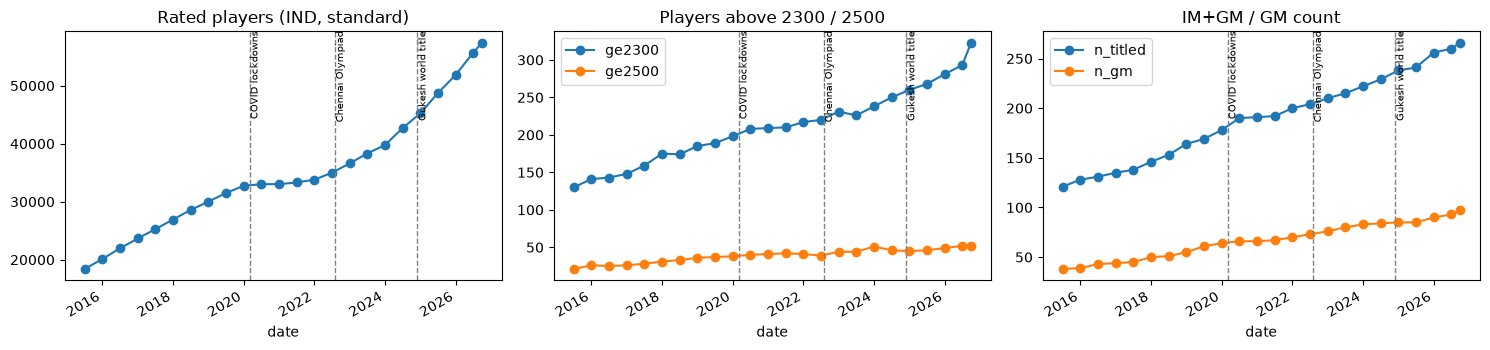

,n_rated,n_active_guess,ge2000,ge2300,ge2500,ge2700,n_titled,n_gm,top10_mean
date,,,,,,,,,
2015-07-01,18396,10169,1365,130,21,2,121,38,2656.5
2016-01-01,20123,10171,1354,141,26,2,128,39,2662.5
2016-07-01,21972,10981,1358,143,25,2,131,43,2669.0
2017-01-01,23660,11456,1360,148,26,2,135,44,2673.6
2017-07-01,25270,11520,1387,159,28,2,138,45,2674.6
2018-01-01,26929,11812,1385,175,31,3,146,50,2673.4
2018-07-01,28576,12148,1392,174,33,3,153,51,2674.5
2019-01-01,30013,12286,1410,185,36,2,164,55,2671.5
2019-07-01,31502,12073,1445,189,37,3,169,61,2667.7


In [3]:
ind = summary[summary.country == "IND"].set_index("date")
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
ind["n_rated"].plot(ax=axes[0], marker="o", title=f"Rated players (IND, {FORMAT})")
ind[["ge2300", "ge2500"]].plot(ax=axes[1], marker="o", title="Players above 2300 / 2500")
ind[["n_titled", "n_gm"]].plot(ax=axes[2], marker="o", title="IM+GM / GM count")
for ax in axes:
    mark_events(ax)
plt.tight_layout(); plt.show()
ind[["n_rated", "n_active_guess", "ge2000", "ge2300", "ge2500", "ge2700", "n_titled", "n_gm", "top10_mean"]].round(1)

**Notes (India):** is growth smooth or does it bend after a particular year?

## 3. Pool vs strength (Member 2)
If the pool grows but the *share* of strong players stays flat, the rise is mostly participation (H1). If the share rises, strength is improving (H2).

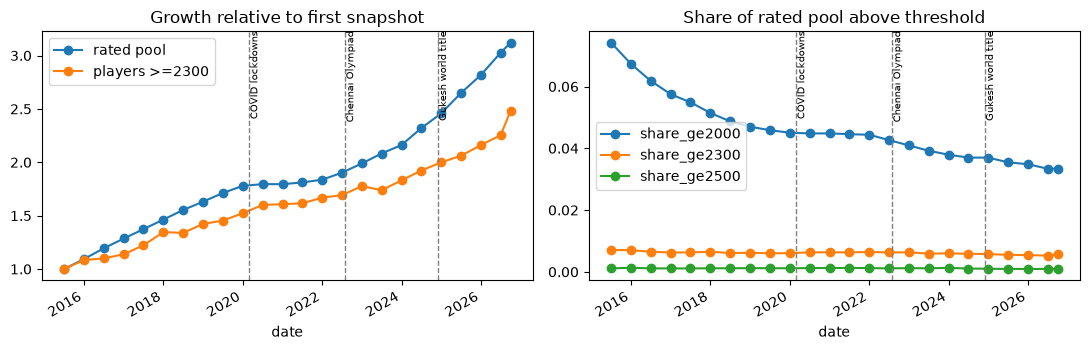

In [4]:
ind = ind.copy()
for t in [2000, 2300, 2500]:
    ind[f"share_ge{t}"] = ind[f"ge{t}"] / ind["n_rated"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
(ind["n_rated"] / ind["n_rated"].iloc[0]).plot(ax=axes[0], label="rated pool", marker="o")
(ind["ge2300"] / ind["ge2300"].iloc[0].clip(min=1)).plot(ax=axes[0], label="players >=2300", marker="o")
axes[0].set_title("Growth relative to first snapshot"); axes[0].legend()
ind[["share_ge2000", "share_ge2300", "share_ge2500"]].plot(ax=axes[1], marker="o", title="Share of rated pool above threshold")
for ax in axes:
    mark_events(ax)
plt.tight_layout(); plt.show()

**Notes (pool vs share):** which grew faster, the pool or the strong tail?

## 4. Comparison federations and India's share of the world (Member 3)
The federations below are placeholders; change them once you decide on a benchmark group.

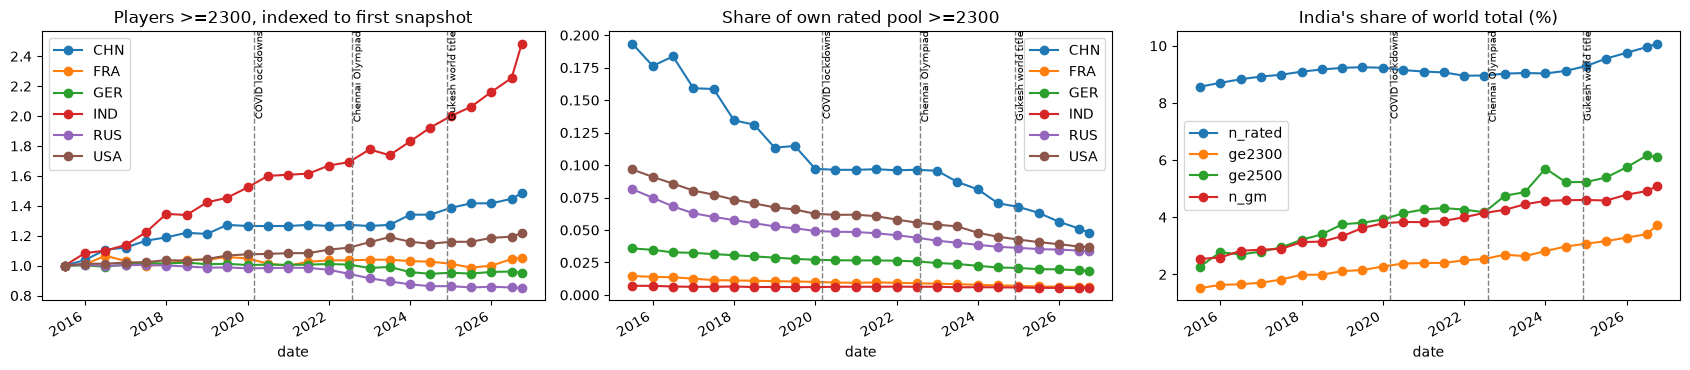

,n_rated,ge2300,ge2500,n_gm
date,,,,
2015-07-01,8.57,1.52,2.27,2.54
2016-01-01,8.70,1.63,2.78,2.59
2016-07-01,8.83,1.65,2.69,2.83
2017-01-01,8.92,1.71,2.80,2.86
2017-07-01,8.99,1.82,2.94,2.89
2018-01-01,9.10,1.99,3.21,3.13
2018-07-01,9.17,1.99,3.40,3.15
2019-01-01,9.23,2.11,3.75,3.34
2019-07-01,9.25,2.15,3.81,3.62


In [5]:
COMPARE = ["IND", "CHN", "USA", "RUS", "GER", "FRA"]
sub = summary[summary.country.isin(COMPARE)]
fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
for ctry, g in sub.groupby("country"):
    g = g.set_index("date")
    base = g["ge2300"].iloc[0]
    if base > 0:
        (g["ge2300"] / base).plot(ax=axes[0], label=ctry, marker="o")
    (g["ge2300"] / g["n_rated"]).plot(ax=axes[1], label=ctry, marker="o")
axes[0].set_title("Players >=2300, indexed to first snapshot"); axes[0].legend()
axes[1].set_title("Share of own rated pool >=2300"); axes[1].legend()
tot = summary.groupby("date")[["n_rated", "ge2300", "ge2500", "n_gm"]].sum()
share_world = (summary[summary.country == "IND"].set_index("date")[["n_rated", "ge2300", "ge2500", "n_gm"]] / tot).mul(100)
share_world.plot(ax=axes[2], marker="o", title="India's share of world total (%)")
for ax in axes:
    mark_events(ax)
plt.tight_layout(); plt.show()
share_world.round(2)

**Notes (comparison):** does India look different from the others after 2020? Is India's share of the world's strong players rising, or only its share of rated players? Rating inflation or rule changes could affect all federations.

## 5. Standard vs rapid vs blitz (all members)
India in each of the three FIDE lists. Do the formats tell the same story? Rapid and blitz lists are smaller and the ratings behave differently, so compare trends and shares, not raw levels.

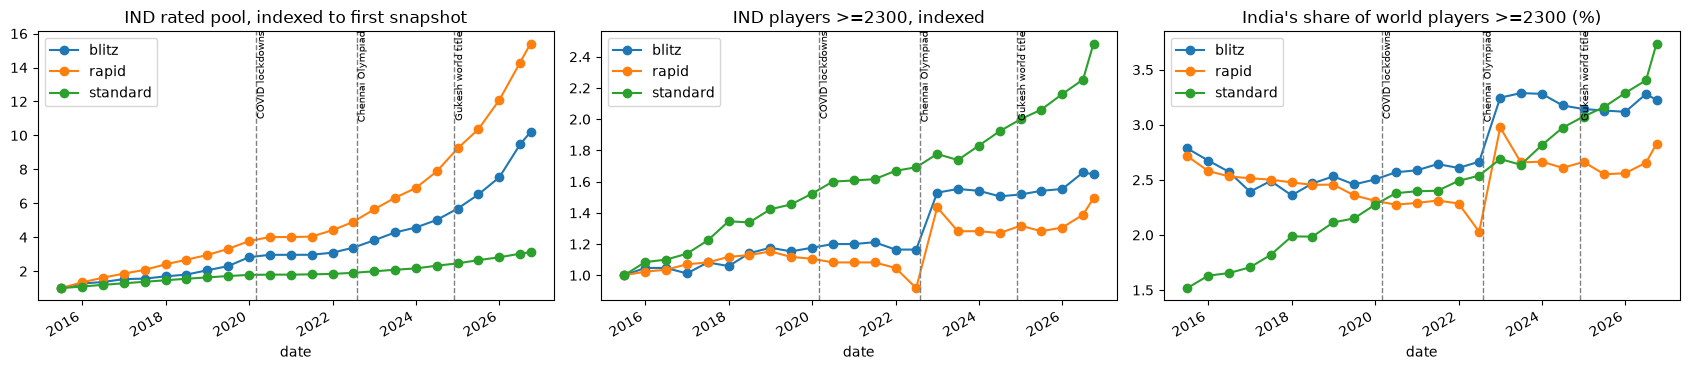

ge2300                 ge2500                 n_rated           \
format      blitz  rapid standard  blitz rapid standard    blitz    rapid   
date                                                                        
2015-07-01   85.0   85.0    130.0   21.0  20.0     21.0   1832.0   2787.0   
2016-01-01   89.0   87.0    141.0   21.0  20.0     26.0   2327.0   3743.0   
2016-07-01   89.0   88.0    143.0   22.0  19.0     25.0   2494.0   4505.0   
2017-01-01   86.0   91.0    148.0   22.0  19.0     26.0   2804.0   5184.0   
2017-07-01   92.0   92.0    159.0   23.0  21.0     28.0   2860.0   5784.0   
2018-01-01   90.0   95.0    175.0   23.0  19.0     31.0   3104.0   6701.0   
2018-07-01   97.0   96.0    174.0   21.0  19.0     33.0   3293.0   7450.0   
2019-01-01  100.0   98.0    185.0   21.0  21.0     36.0   3760.0   8235.0   
2019-07-01   98.0   95.0    189.0   20.0  21.0     37.0   4206.0   9224.0   
2020-01-01  100.0   94.0    198.0   25.0  19.0     38.0   5172.0  10511.0   
2020-07-01  102.0   92.0    208.0   23.0  18.0     40.0   5427.0  11177.0   
2021-01-01  102.0   92.0    209.0   23.0  18.0     41.0   5427.0  11175.0   
2021-07-01  103.0   92.0    210.0   23.0  18.0     42.0   5433.0  11251.0   
2022-01-01   99.0   89.0    217.0   24.0  23.0     41.0   5660.0  12297.0   
2022-07-01   99.0   78.0    220.0   24.0  21.0     39.0   6195.0  13660.0   
2023-01-01  130.0  122.0    231.0   25.0  25.0     44.0   6997.0  15721.0   
2023-07-01  132.0  109.0    226.0   25.0  24.0     44.0   7838.0  17609.0   
2024-01-01  131.0  109.0    238.0   25.0  24.0     51.0   8376.0  19238.0   
2024-07-01  128.0  108.0    250.0   25.0  24.0     46.0   9186.0  21945.0   
2025-01-01  129.0  112.0    260.0   25.0  26.0     45.0  10417.0  25734.0   
2025-07-01  131.0  109.0    268.0   26.0  27.0     46.0  11940.0  28879.0   
2026-01-01  132.0  111.0    281.0   26.0  29.0     49.0  13800.0  33682.0   
2026-07-01  141.0  118.0    293.0   27.0  28.0     52.0  17337.0  39817.0   
2026-10-01  140.0  127.0    323.0   28.0  29.0     52.0  18692.0  42950.0   

                     
format     standard  
date                 
2015-07-01  18396.0  
2016-01-01  20123.0  
2016-07-01  21972.0  
2017-01-01  23660.0  
2017-07-01  25270.0  
2018-01-01  26929.0  
2018-07-01  28576.0  
2019-01-01  30013.0  
2019-07-01  31502.0  
2020-01-01  32730.0  
2020-07-01  33027.0  
2021-01-01  33023.0  
2021-07-01  33318.0  
2022-01-01  33800.0  
2022-07-01  34996.0  
2023-01-01  36602.0  
2023-07-01  38306.0  
2024-01-01  39771.0  
2024-07-01  42691.0  
2025-01-01  45245.0  
2025-07-01  48735.0  
2026-01-01  51859.0  
2026-07-01  55690.0  
2026-10-01  57412.0

In [6]:
ind_all = all_formats[all_formats.country == "IND"]
world = all_formats.groupby(["format", "date"])[["n_rated", "ge2300", "ge2500", "n_gm"]].sum()
fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
for fmt, g in ind_all.groupby("format"):
    g = g.set_index("date")
    (g["n_rated"] / g["n_rated"].iloc[0]).plot(ax=axes[0], label=fmt, marker="o")
    (g["ge2300"] / g["ge2300"].iloc[0].clip(min=1)).plot(ax=axes[1], label=fmt, marker="o")
    w = world.loc[fmt]
    (g["ge2300"] / w["ge2300"].reindex(g.index) * 100).plot(ax=axes[2], label=fmt, marker="o")
axes[0].set_title("IND rated pool, indexed to first snapshot"); axes[0].legend()
axes[1].set_title("IND players >=2300, indexed"); axes[1].legend()
axes[2].set_title("India's share of world players >=2300 (%)"); axes[2].legend()
for ax in axes:
    mark_events(ax)
plt.tight_layout(); plt.show()
ind_all.pivot_table(index="date", columns="format", values=["n_rated", "ge2300", "ge2500"]).round(0)

**Notes (formats):** which format grew fastest? Did rapid and blitz react to COVID and online chess differently from standard?

## 6. What we learned and next steps (all)
- Data coverage and problems (archive from Feb 2015, `flag` / active counts, any missing lists):
- Main patterns by format:
- Surprises:
- Plan for Checkpoint 2 (event analysis, statistical tests, final charts):